In [52]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.dates as mdates


In [53]:
# Helper functions

def timeColumn2DateTime(df):
    df['Time'] = df['Time'].astype(str)
    df['Time'] = df['Time'].str.replace('T', ' ')
    df['Time'] = df['Time'].str.replace('Z', '')
    df['Time']= pd.to_datetime(df['Time'])
    return df


def iqd2hourly(df, parameter,iqd, no_duplicate=11 ):

    # il_filtered_df_hr = il_filtered_df.groupby(pd.Grouper(freq='h')).mean()
    # il_filtered_df_hr = il_filtered_df.resample(pd.Timedelta(hours=1)).mean(min_count=1)

    # Convert to hourly (data resampling)
    df_hr = df.resample("h").mean()  # chage "H" to "h" if error
    
    df_parameter  = df_hr[parameter]
    
    # Filter the iqd days
    df_parameter = df_parameter[df_parameter.index.day.isin(iqd)]
    
    # Group by the hour of the day (0 to 23) and find the average for each hour across all days
    df_parameter = df_parameter.groupby(df_parameter.index.hour).mean()
    #print(df_parameter)
    
    # Duplicates the df_parameter
    df_parameter_duplicated = np.tile(df_parameter, no_duplicate)
    return df_parameter_duplicated



In [54]:
iqd_df=pd.read_csv(r"C:\Users\P C\OneDrive\Documents\ernest1\data\q-value\Q-2019.csv")
#iqd_df.fillna(0, inplace=True)
ji_df=pd.read_csv(r"C:\Users\P C\OneDrive\Documents\ernest1\data\JI\DINDataJI2019.csv")
#ji_df.fillna(0, inplace=True)
il_df=pd.read_csv(r"C:\Users\P C\OneDrive\Documents\ernest1\data\IL\DINDataIL2019.csv")
#il_df.fillna(0, inplace=True)
BzKpDst_df = pd.read_csv(r"C:\Users\P C\OneDrive\Documents\ernest1\data\para\2019-Parameter4.csv")


In [55]:
#getting NmF2
ji_df["NmF2"] = pow(ji_df["foF2"], 2) * 1.24e10
il_df["NmF2"] = pow(il_df["foF2"], 2) * 1.24e10

In [56]:
iqd_df.head(12)
print(iqd_df.columns)


Index(['YYYY', 'MM', 'q1', 'q2', 'q3', 'q4', 'q5', 'q6', 'q7', 'q8', 'q9',
       'q0', 'd1', 'd2', 'd3', 'd4', 'd5'],
      dtype='str')


In [57]:
print(ji_df.head(3))
print(il_df.head(3))

                       Time     CS  foF2   MUFD  foF2p   hmF2    B0  \
0  2019-01-01T00:00:00.000Z  100.0   7.0  23.42   7.45  279.3  53.5   
1  2019-01-01T00:15:00.000Z  100.0   6.7  24.55   7.26  261.4  33.4   
2  2019-01-01T00:30:00.000Z  100.0   6.8  23.28   7.06  277.8  47.5   

           NmF2  
0  6.076000e+11  
1  5.566360e+11  
2  5.733760e+11  
                       Time  CS  foF2  MUFD  foF2p  hmF2  B0  NmF2
0  2019-01-01T00:00:00.000Z NaN   NaN   NaN    NaN   NaN NaN   NaN
1  2019-01-01T00:15:00.000Z NaN   NaN   NaN    NaN   NaN NaN   NaN
2  2019-01-01T00:30:00.000Z NaN   NaN   NaN    NaN   NaN NaN   NaN


In [58]:
# Conver Time column to Date Time Object

ji_df = timeColumn2DateTime(ji_df)
il_df = timeColumn2DateTime(il_df)

ji_df.head()

,Time,CS,foF2,MUFD,foF2p,hmF2,B0,NmF2
0,2019-01-01 00:00:00,100.0,7.0,23.42,7.45,279.3,53.5,6.076000e+11
1,2019-01-01 00:15:00,100.0,6.7,24.55,7.26,261.4,33.4,5.566360e+11
2,2019-01-01 00:30:00,100.0,6.8,23.28,7.06,277.8,47.5,5.733760e+11
3,2019-01-01 00:45:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2019-01-01 01:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [59]:
#selected month
selected_months= 5
iqd__row=iqd_df[iqd_df['MM']==selected_months]
print(iqd__row)

iqd_columns=['q1', 'q2', 'q3', 'q4', 'q5', 'q6', 'q7', 'q8', 'q9','q0']

iqd=iqd__row[iqd_columns].values[0]

print(f"The quiet days in month {selected_months} are: {iqd}")

   YYYY  MM  q1  q2  q3  q4  q5  q6  q7  q8  q9  q0  d1  d2  d3  d4  d5
4  2019   5   8  19   5  21  25  31  22  12  18  17  14  11  29   1   2
The quiet days in month 5 are: [ 8 19  5 21 25 31 22 12 18 17]


In [60]:
#using iqd to filter df for the selected month and quiet days
il_filtered_df=il_df[(il_df['Time'].dt.month == selected_months) & 
               (il_df['Time'].dt.day.isin(iqd))]
ji_filtered_df=ji_df[(ji_df['Time'].dt.month == selected_months) & 
               (ji_df['Time'].dt.day.isin(iqd))]
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)


print("ILORIN_IQD:", il_filtered_df.shape)
print("JICAMARCA_IQD:", ji_filtered_df.shape)


ILORIN_IQD: (960, 8)
JICAMARCA_IQD: (960, 8)


In [61]:
# Set Index
# Make the time as the index of the dataframe
il_filtered_df = il_filtered_df.set_index('Time')
ji_filtered_df = ji_filtered_df.set_index('Time')


In [62]:
# Filtering parameter of interest and hourly values of the iqd

il_hmF2 = iqd2hourly(il_filtered_df,"hmF2", iqd)
ji_hmF2 = iqd2hourly(ji_filtered_df,"hmF2", iqd)

time = np.arange(0, len(il_hmF2))


print("ILORIN_IQD:", il_hmF2.shape)
print("JICAMARCA_IQD:", ji_hmF2.shape)



ILORIN_IQD: (264,)
JICAMARCA_IQD: (264,)


In [63]:
def cal_storm(df, parameter, storm, no_duplicate=11 ):

    # il_filtered_df_hr = il_filtered_df.groupby(pd.Grouper(freq='h')).mean()
    # il_filtered_df_hr = il_filtered_df.resample(pd.Timedelta(hours=1)).mean(min_count=1)

    # Convert to hourly (data resampling)
    df_hr = df.resample("h").mean()  # chage "H" to "h" if error
    
    df_parameter  = df_hr[parameter]

    # Filter the storm days
    df_parameter = df_parameter[df_parameter.index.day.isin(storm)]
    x_axis = df_parameter.index
    # Group by the hour of the day (0 to 23) and find the average for each hour across all days
    df_parameter = df_parameter.groupby(df_parameter.index.hour).mean()
    
    # Duplicates the df_parameter
    df_parameter_duplicated = np.tile(df_parameter, no_duplicate)
    return df_parameter_duplicated, x_axis

In [64]:
#storm days for ilorin
il_storm_days = [9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]
#selected month
sel_month = 5
#data relating to the storm days 
il_storm_df = None
#for loop to get the stom days
for idx, i in enumerate(il_storm_days):
    il_storm_df1 = None
    """
    if idx >= 2:
        sel_month = 11
        il_storm_df1 = il_df.loc[(il_df['Time'].dt.month==sel_month) & (il_df['Time'].dt.day==i)]
    else:
        il_storm_df1 = il_df.loc[(il_df['Time'].dt.month==sel_month) & (il_df['Time'].dt.day==i)]
    """
    il_storm_df1 = il_df.loc[(il_df['Time'].dt.month==sel_month) & (il_df['Time'].dt.day==i)]
    il_storm_df = pd.concat([il_storm_df, il_storm_df1])
#print(il_storm_df.head())

il_storm_df = il_storm_df.set_index('Time')

il_filtered_storm_df, il_x_axis = cal_storm(il_storm_df, "hmF2", il_storm_days)
#print(x_axis)



In [65]:
#storm days for jicamaca
ji_storm_days = [9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]
#selected month
sel_month = 5
#data relating to the storm days 
ji_storm_df = None
#for loop to get the stom days
for idx, i in enumerate(ji_storm_days):
    ji_storm_df1 = None
    """
    if idx >= 2:
        sel_month = 11
        ji_storm_df1 = ji_df.loc[(ji_df['Time'].dt.month==sel_month) & (ji_df['Time'].dt.day==i)]
    else:
        ji_storm_df1 = ji_df.loc[(ji_df['Time'].dt.month==sel_month) & (ji_df['Time'].dt.day==i)]
    """
    ji_storm_df1 = ji_df.loc[(ji_df['Time'].dt.month==sel_month) & (ji_df['Time'].dt.day==i)]
    ji_storm_df = pd.concat([ji_storm_df, ji_storm_df1])
#print(ji_storm_df.head())

ji_storm_df = ji_storm_df.set_index('Time')

ji_filtered_storm_df, ji_x_axis = cal_storm(ji_storm_df, "hmF2", ji_storm_days)
#print(f"lenght: {len(ji_filtered_storm_df)}")

In [66]:
#code to generate or relating to Bz, Kp, Dst

#creating array of names to be used
column_names = ["BZ,nT", "Kp Index", "Dst-index, nT", "SW Plasma Speed, Km/s", "E electric Field", "Flow pressure"]
title_names = ["BZ, nT (GSM)", "Kp index x 10", "Dst-index, nT", "SW Plasma Speed, Km/s", "E electric Field", "Flow pressure"]
lin_label = ["Storm threshold (-5 nT)", "Minor storm (Kp = 40)", "Moderate storm (-30 nT)"]

"""
#creating x_axis points 
date_range = pd.date_range(start="2021-10-30", end="2021-11-09", freq="D")
#print(date_range)
#x_axis points
x_axis = []
for date in date_range:
    for _ in range(24):
        x_axis.append(date)
#print(x_axis)
"""

hr_line = [-5, 40, -30]

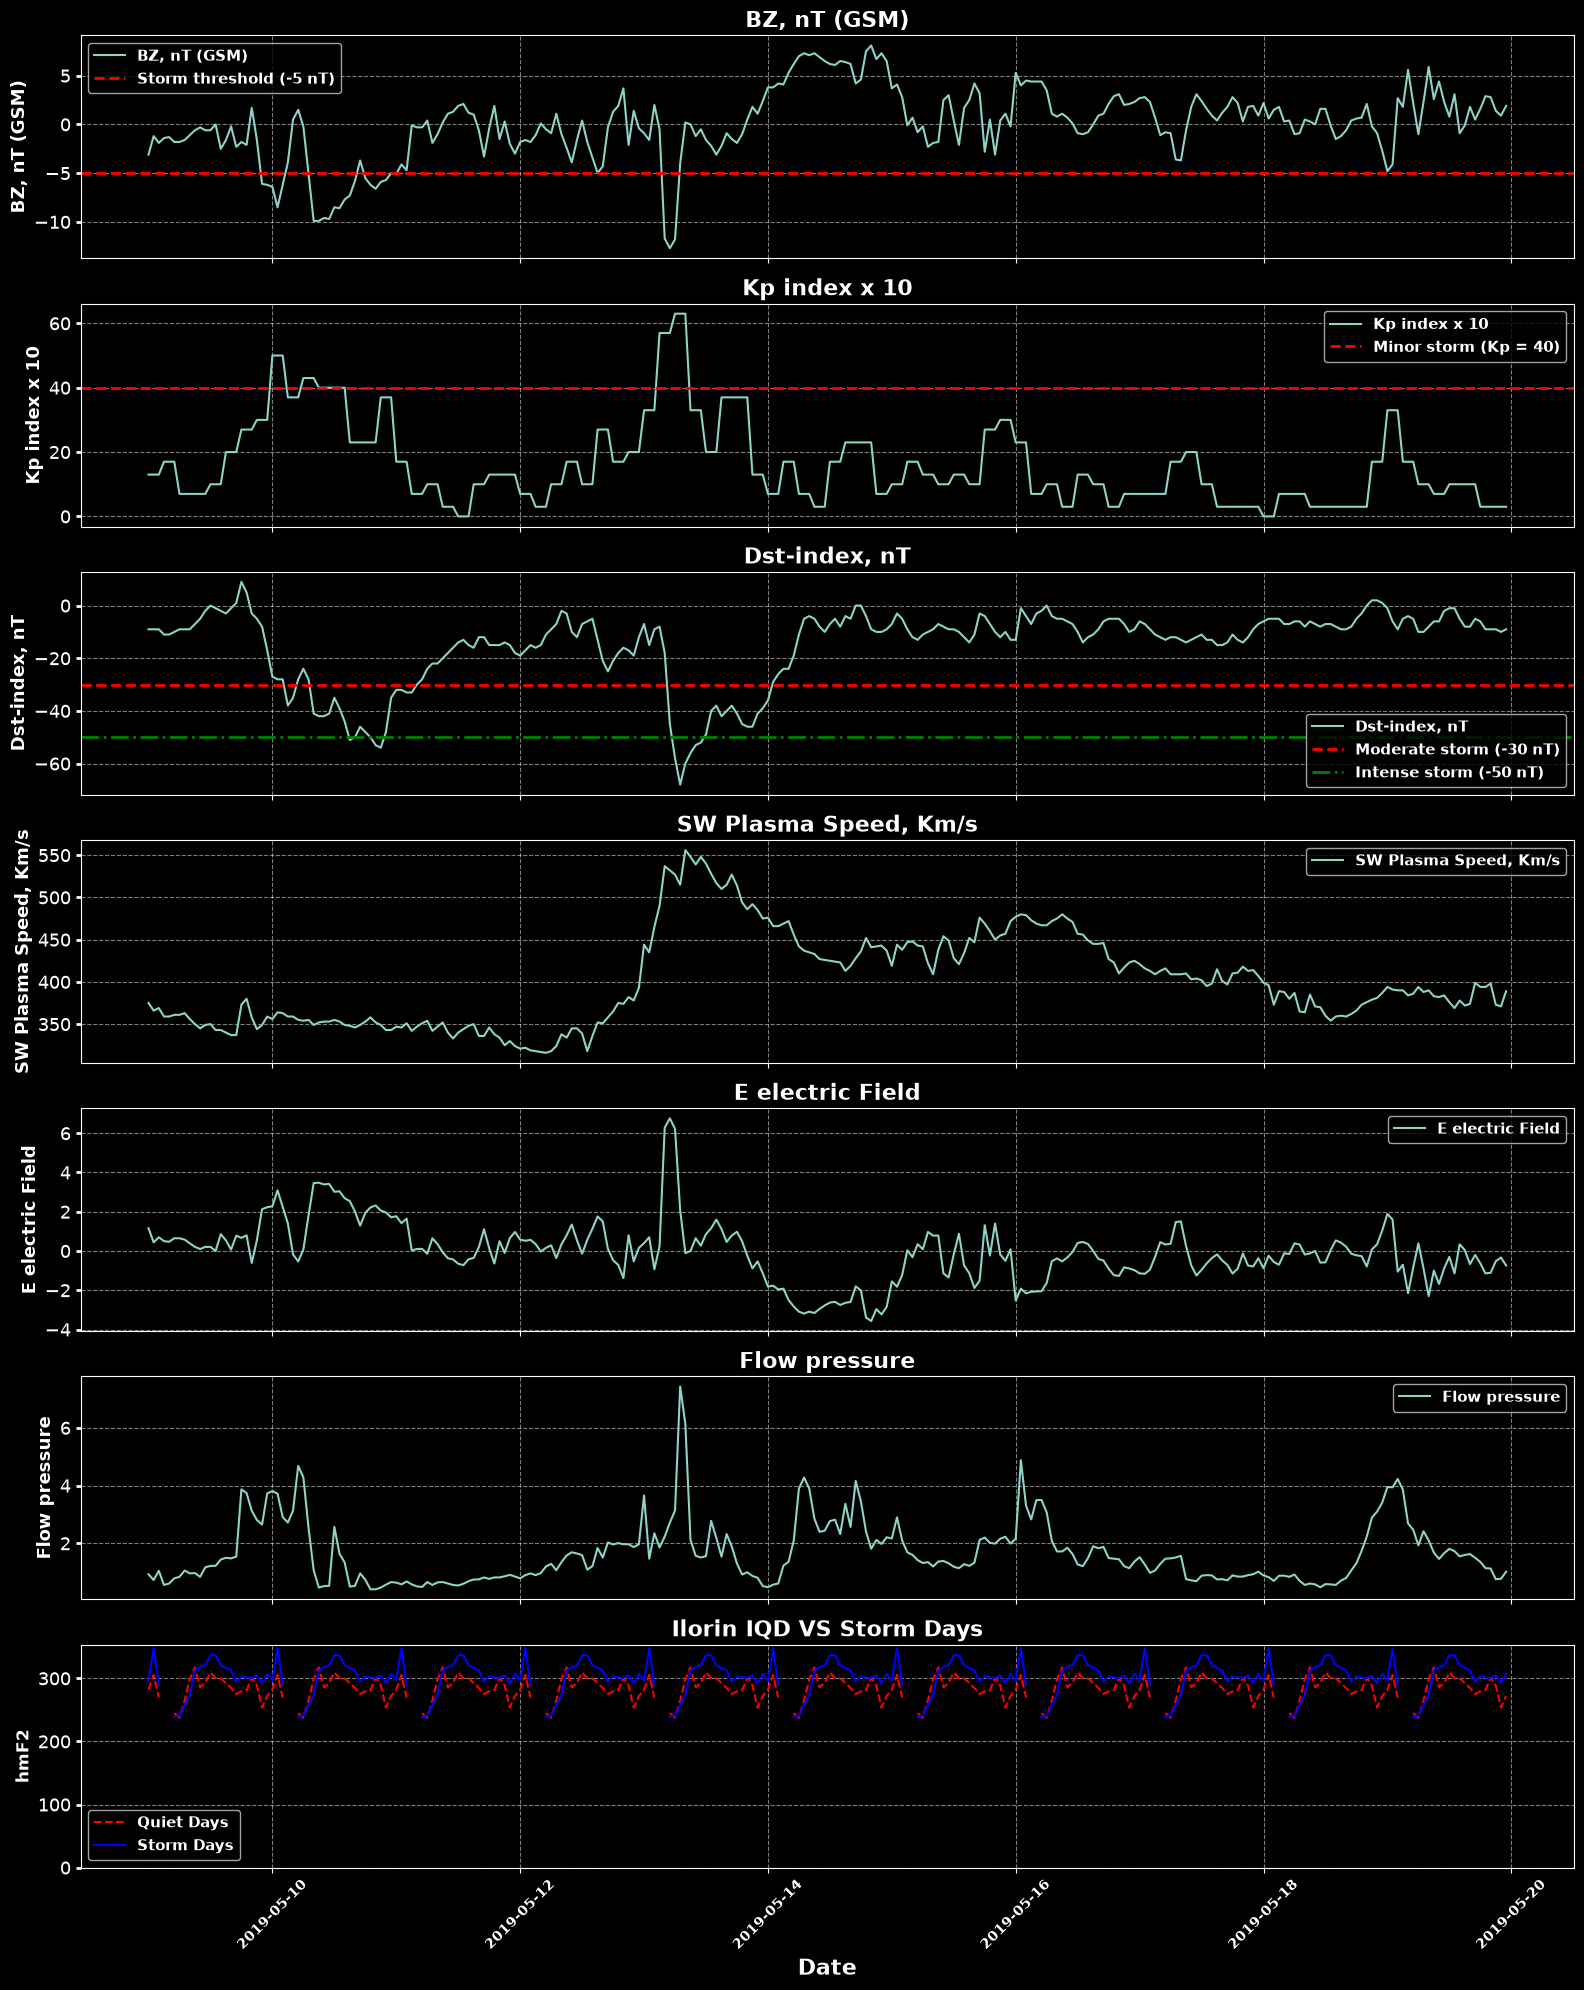

In [67]:

#creating a grid of 4 by 1 to plot Bz, Kp, Dst and ...
fig, axes = plt.subplots(7, 1, figsize=(16, 20), sharex=True)
#for loop to plot Bz, Kp and Dst graph
for idx, name in enumerate(column_names):
    ax = axes[idx]
    ax.plot(il_x_axis,  BzKpDst_df[name], ls="-", label=title_names[idx])
    ax.set_title(title_names[idx], fontsize=16, fontweight="bold")
    ax.set_ylabel(title_names[idx], fontsize=13, fontweight="bold")

    #Threshold line
    if idx < 3:
        ax.axhline(y=hr_line[idx], color="red", linestyle="--", linewidth=2, label=lin_label[idx])
    if name == "Dst-index, nT":
        ax.axhline(y=-50, color="green", linestyle="-.", linewidth=2, label="Intense storm (-50 nT)")
        
    #x_axis labelling 
    ax.tick_params(axis="y", labelsize=13, width=2)
    ax.legend(prop={"weight": "bold", "size": 11})
axes[6].plot(il_x_axis, il_hmF2, c="red", lw=1.5, ls="--", label="Quiet Days")
axes[6].plot(il_x_axis, il_filtered_storm_df, c="b", lw=1.5, label="Storm Days")
axes[6].set_title("Ilorin IQD VS Storm Days", fontsize=16, fontweight="bold")
axes[6].set_ylabel("hmF2", fontsize=12, fontweight="bold")
axes[6].tick_params(axis="y", labelsize=13, width=2)
plt.ylim(bottom=0)
for i in range(7):
    axes[i].grid(True, linestyle="--", alpha=0.5)
axes[6].legend(prop={"weight": "bold", "size": 11})
axes[-1].set_xlabel("Date", fontsize=16, fontweight="bold")
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m-%d"))
axes[-1].xaxis.set_major_locator(mdates.DayLocator(interval=2))
plt.setp(axes[-1].xaxis.get_majorticklabels(), rotation=45, fontweight="bold")
plt.tight_layout()
plt.show()

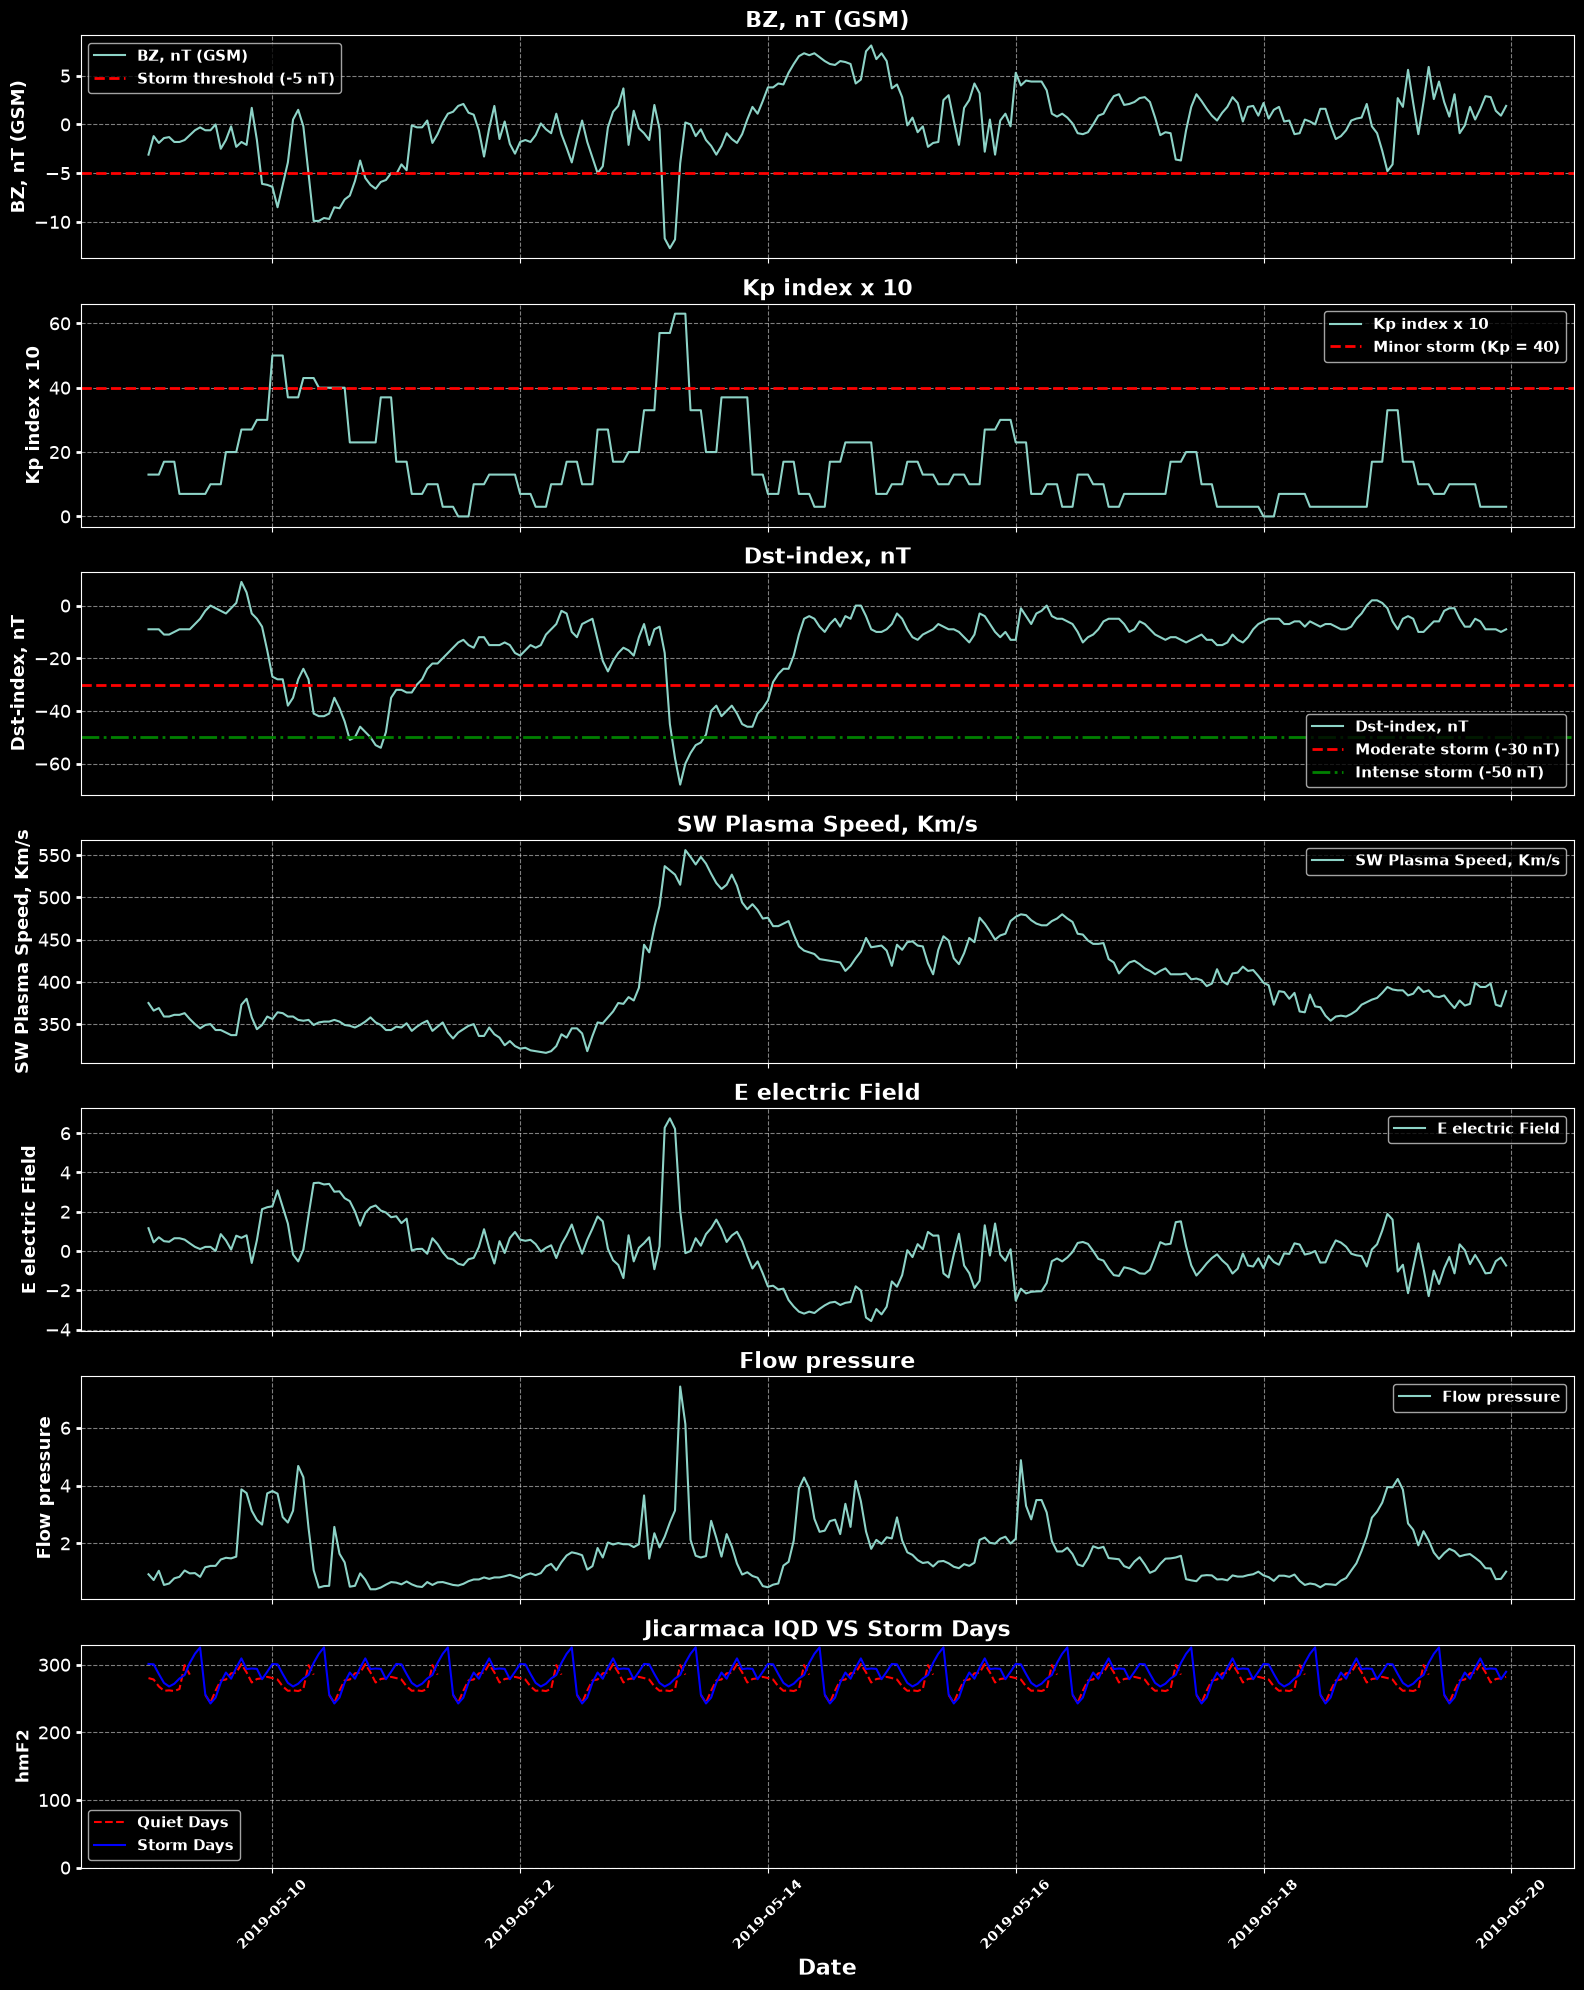

In [68]:

#creating a grid of 4 by 1 to plot Bz, Kp, Dst and ...
fig, axes = plt.subplots(7, 1, figsize=(16, 20), sharex=True)
#for loop to plot Bz, Kp and Dst graph
for idx, name in enumerate(column_names):
    ax = axes[idx]
    ax.plot(ji_x_axis,  BzKpDst_df[name], ls="-", label=title_names[idx])
    ax.set_title(title_names[idx], fontsize=16, fontweight="bold")
    ax.set_ylabel(title_names[idx], fontsize=13, fontweight="bold")

    #Threshold line
    if idx < 3:
        ax.axhline(y=hr_line[idx], color="red", linestyle="--", linewidth=2, label=lin_label[idx])
    if name == "Dst-index, nT":
        ax.axhline(y=-50, color="green", linestyle="-.", linewidth=2, label="Intense storm (-50 nT)")
        
    #x_axis labelling 
    ax.tick_params(axis="y", labelsize=13, width=2)
    ax.legend(prop={"weight": "bold", "size": 11})
axes[6].plot(ji_x_axis, ji_hmF2, c="red", lw=1.5, ls="--", label="Quiet Days")
axes[6].plot(ji_x_axis, ji_filtered_storm_df, c="b", lw=1.5, label="Storm Days")
axes[6].set_title("Jicarmaca IQD VS Storm Days", fontsize=16, fontweight="bold")
axes[6].set_ylabel("hmF2", fontsize=12, fontweight="bold")
axes[6].tick_params(axis="y", labelsize=13, width=2)
plt.ylim(bottom=0)
for i in range(7):
    axes[i].grid(True, linestyle="--", alpha=0.5)
axes[6].legend(prop={"weight": "bold", "size": 11})
axes[-1].set_xlabel("Date", fontsize=16, fontweight="bold")
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m-%d"))
axes[-1].xaxis.set_major_locator(mdates.DayLocator(interval=2))
plt.setp(axes[-1].xaxis.get_majorticklabels(), rotation=45, fontweight="bold")
plt.tight_layout()
plt.show()